In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, StringType

from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler,
    StandardScaler
)

from pyspark.ml.classification import (
    LogisticRegression,
    DecisionTreeClassifier,
    LinearSVC,
    NaiveBayes
)

from pyspark.ml.regression import (
    LinearRegression,
    DecisionTreeRegressor
)

from pyspark.ml.clustering import KMeans

from pyspark.ml.evaluation import (
    MulticlassClassificationEvaluator,
    RegressionEvaluator
)

sns.set_theme(style="whitegrid")

spark = (
    SparkSession.builder
    .appName("CampusPlacementPrediction")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Spark Version:", spark.version)

Spark Version: 3.5.9


In [2]:
csv_path = r"C:\Users\putlu\Downloads\archive (2)\campus_placement_data.csv"

df = spark.read.csv(
    csv_path,
    header=True,
    inferSchema=True
)

print("Total records:", df.count())
df.printSchema()

Total records: 100000
root
 |-- student_id: string (nullable = true)
 |-- gender: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- city_tier: string (nullable = true)
 |-- ssc_percentage: double (nullable = true)
 |-- ssc_board: string (nullable = true)
 |-- hsc_percentage: double (nullable = true)
 |-- hsc_board: string (nullable = true)
 |-- hsc_stream: string (nullable = true)
 |-- degree_percentage: double (nullable = true)
 |-- degree_field: string (nullable = true)
 |-- mba_percentage: double (nullable = true)
 |-- specialization: string (nullable = true)
 |-- internships_count: integer (nullable = true)
 |-- projects_count: integer (nullable = true)
 |-- certifications_count: integer (nullable = true)
 |-- technical_skills_score: double (nullable = true)
 |-- soft_skills_score: double (nullable = true)
 |-- aptitude_score: double (nullable = true)
 |-- communication_score: double (nullable = true)
 |-- work_experience_months: integer (nullable = true)
 |-- leade

In [3]:
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    Imputer,
    StringIndexer,
    OneHotEncoder,
    VectorAssembler
)

# --------------------------------------------------
# STEP 1: Remove duplicate records
# --------------------------------------------------

df = df.dropDuplicates()

# --------------------------------------------------
# STEP 2: Define numerical and categorical features
# --------------------------------------------------

numeric_cols = [
    "age",
    "ssc_percentage",
    "hsc_percentage",
    "degree_percentage",
    "mba_percentage",
    "internships_count",
    "projects_count",
    "certifications_count",
    "technical_skills_score",
    "soft_skills_score",
    "aptitude_score",
    "communication_score",
    "work_experience_months",
    "leadership_roles",
    "extracurricular_activities",
    "backlogs"
]

categorical_cols = [
    "gender",
    "city_tier",
    "ssc_board",
    "hsc_board",
    "hsc_stream",
    "degree_field",
    "specialization"
]

# --------------------------------------------------
# STEP 3: Convert numerical columns to double
# Replace NaN and infinity with null
# --------------------------------------------------

for col in numeric_cols + ["salary_lpa"]:

    df = df.withColumn(
        col,
        F.when(
            F.isnan(F.col(col).cast("double")) |
            (F.col(col).cast("double") == float("inf")) |
            (F.col(col).cast("double") == float("-inf")),
            F.lit(None).cast("double")
        ).otherwise(
            F.col(col).cast("double")
        )
    )

# --------------------------------------------------
# STEP 4: Convert placement target
# --------------------------------------------------

df = df.withColumn(
    "placed",
    F.col("placed").cast("double")
)

# Keep only valid placement labels
df = df.filter(
    F.col("placed").isin([0.0, 1.0])
)

# Fill missing categorical values
df = df.fillna({
    col: "Unknown" for col in categorical_cols
})

print("Cleaned dataset records:", df.count())

df.show(5, truncate=False)

Cleaned dataset records: 100000
+----------+------+----+---------+--------------+---------+--------------+---------+----------+-----------------+------------+--------------+--------------+-----------------+--------------+--------------------+----------------------+-----------------+--------------+-------------------+----------------------+----------------+--------------------------+--------+------+----------+
|student_id|gender|age |city_tier|ssc_percentage|ssc_board|hsc_percentage|hsc_board|hsc_stream|degree_percentage|degree_field|mba_percentage|specialization|internships_count|projects_count|certifications_count|technical_skills_score|soft_skills_score|aptitude_score|communication_score|work_experience_months|leadership_roles|extracurricular_activities|backlogs|placed|salary_lpa|
+----------+------+----+---------+--------------+---------+--------------+---------+----------+-----------------+------------+--------------+--------------+-----------------+--------------+-----------------

In [4]:
# 80% training, 20% testing
train_df, test_df = df.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training records:", train_df.count())
print("Testing records:", test_df.count())

Training records: 80200
Testing records: 19800


In [5]:
from pyspark.ml.feature import Imputer

# Output columns for imputed numerical values
imputed_cols = [
    col + "_imputed" for col in numeric_cols
]

def make_preprocessing_stages():

    # Learn median values from training data
    imputer = Imputer(
        inputCols=numeric_cols,
        outputCols=imputed_cols,
        strategy="median"
    )

    # Convert categorical values to numerical indexes
    indexers = [
        StringIndexer(
            inputCol=col,
            outputCol=col + "_index",
            handleInvalid="keep"
        )
        for col in categorical_cols
    ]

    # One-hot encode categorical variables
    encoder = OneHotEncoder(
        inputCols=[
            col + "_index" for col in categorical_cols
        ],
        outputCols=[
            col + "_encoded" for col in categorical_cols
        ]
    )

    # Combine numerical and categorical features
    assembler = VectorAssembler(
        inputCols=imputed_cols + [
            col + "_encoded" for col in categorical_cols
        ],
        outputCol="features"
    )

    return [imputer] + indexers + [encoder, assembler]

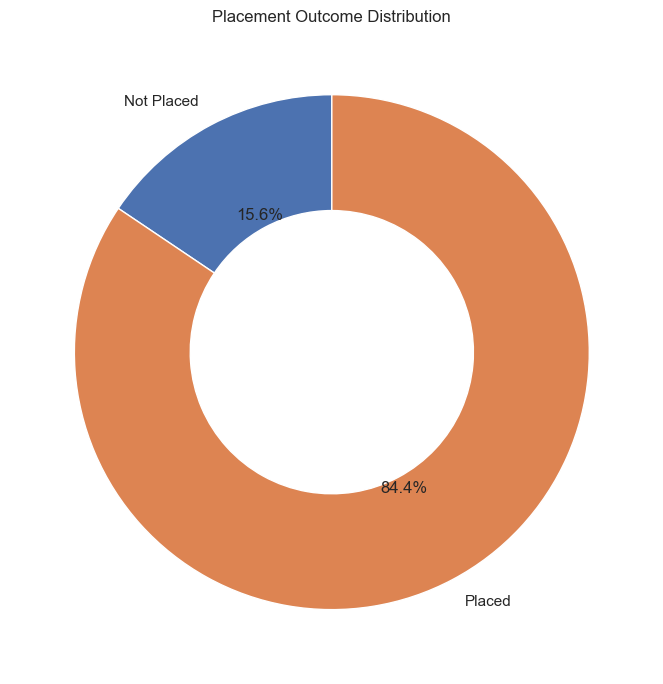

In [6]:
placement_counts = (
    df.groupBy("placed")
      .count()
      .orderBy("placed")
      .toPandas()
)

placement_labels = placement_counts["placed"].map({
    0.0: "Not Placed",
    1.0: "Placed"
})

plt.figure(figsize=(7, 7))

plt.pie(
    placement_counts["count"],
    labels=placement_labels,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.45}
)

plt.title("Placement Outcome Distribution")
plt.tight_layout()
plt.show()

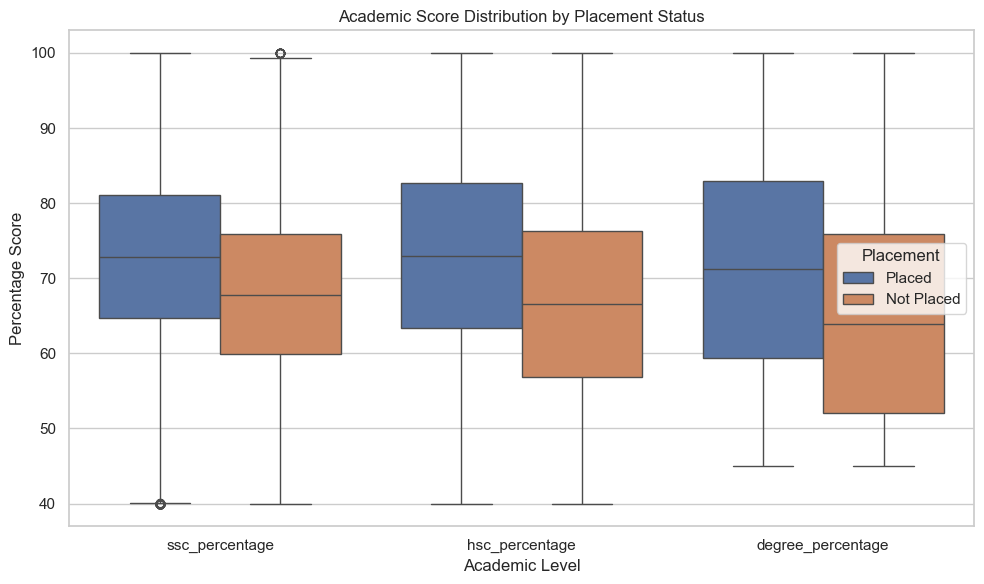

In [7]:
academic_cols = [
    "ssc_percentage",
    "hsc_percentage",
    "degree_percentage"
]

academic_data = (
    df.select("placed", *academic_cols)
      .sample(False, 0.25, seed=42)
      .toPandas()
)

academic_data["Placement"] = academic_data["placed"].map({
    0.0: "Not Placed",
    1.0: "Placed"
})

academic_long = academic_data.melt(
    id_vars="Placement",
    value_vars=academic_cols,
    var_name="Academic Level",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=academic_long,
    x="Academic Level",
    y="Score",
    hue="Placement"
)

plt.title("Academic Score Distribution by Placement Status")
plt.xlabel("Academic Level")
plt.ylabel("Percentage Score")

plt.tight_layout()
plt.show()

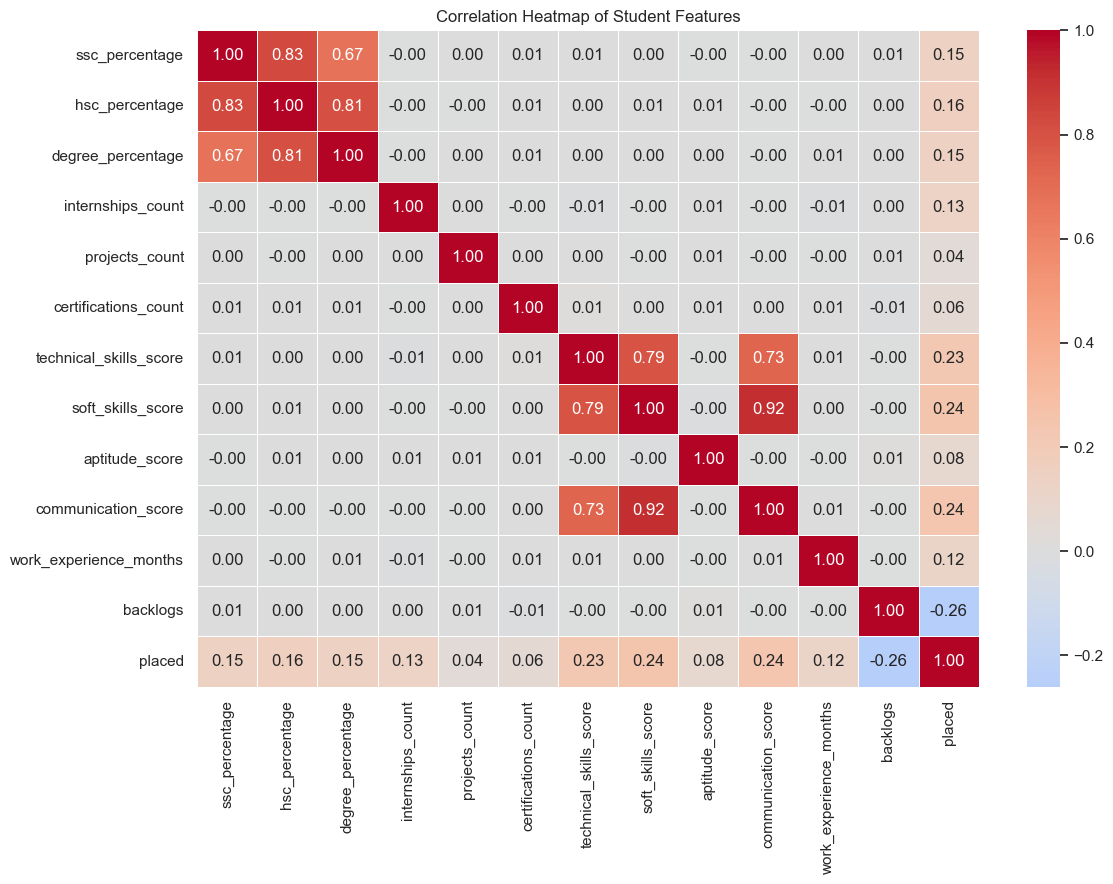

In [8]:
heatmap_cols = [
    "ssc_percentage",
    "hsc_percentage",
    "degree_percentage",
    "internships_count",
    "projects_count",
    "certifications_count",
    "technical_skills_score",
    "soft_skills_score",
    "aptitude_score",
    "communication_score",
    "work_experience_months",
    "backlogs",
    "placed"
]

heatmap_data = (
    df.select(heatmap_cols)
      .sample(False, 0.25, seed=42)
      .toPandas()
)

correlation = heatmap_data.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.4
)

plt.title("Correlation Heatmap of Student Features")
plt.tight_layout()
plt.show()

In [9]:
from pyspark.ml.classification import (
    LogisticRegression,
    DecisionTreeClassifier,
    LinearSVC,
    NaiveBayes
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

classification_models = {
    "Logistic Regression": LogisticRegression(
        labelCol="placed",
        featuresCol="features",
        maxIter=50
    ),

    "Decision Tree": DecisionTreeClassifier(
        labelCol="placed",
        featuresCol="features",
        maxDepth=5,
        seed=42
    ),

    "SVM": LinearSVC(
        labelCol="placed",
        featuresCol="features",
        maxIter=50
    ),

    "Naive Bayes": NaiveBayes(
        labelCol="placed",
        featuresCol="features",
        modelType="multinomial"
    )
}

classification_results = []
classification_predictions = {}
classification_fitted_models = {}

for model_name, model in classification_models.items():

    pipeline = Pipeline(
        stages=make_preprocessing_stages() + [model]
    )

    fitted_model = pipeline.fit(train_df)

    predictions = fitted_model.transform(test_df)

    # Convert only the required columns to Pandas
    prediction_data = (
        predictions
        .select("placed", "prediction")
        .toPandas()
    )

    y_true = prediction_data["placed"]
    y_pred = prediction_data["prediction"]

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    classification_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    classification_predictions[model_name] = predictions
    classification_fitted_models[model_name] = fitted_model

    print("\nModel:", model_name)
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))

classification_results_df = pd.DataFrame(
    classification_results
)

classification_results_df


Model: Logistic Regression
Accuracy: 0.8607
Precision: 0.878
Recall: 0.9701
F1 Score: 0.9218

Model: Decision Tree
Accuracy: 0.8517
Precision: 0.8577
Recall: 0.9887
F1 Score: 0.9185

Model: SVM
Accuracy: 0.846
Precision: 0.846
Recall: 1.0
F1 Score: 0.9166

Model: Naive Bayes
Accuracy: 0.6971
Precision: 0.8907
Recall: 0.7317
F1 Score: 0.8034


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.860707,0.878040,0.970090,0.921772
1,Decision Tree,0.851667,0.857720,0.988657,0.918546
2,SVM,0.845960,0.845960,1.000000,0.916553
3,Naive Bayes,0.697071,0.890698,0.731701,0.803409


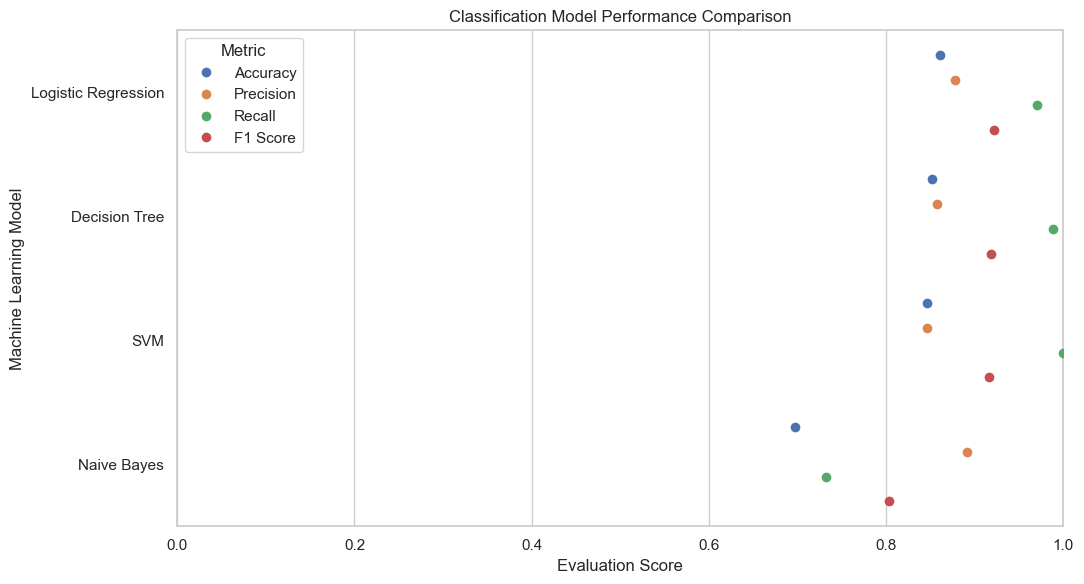

In [10]:
metrics_long = classification_results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.stripplot(
    data=metrics_long,
    x="Score",
    y="Model",
    hue="Metric",
    dodge=True,
    size=7
)

plt.title("Classification Model Performance Comparison")
plt.xlabel("Evaluation Score")
plt.ylabel("Machine Learning Model")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

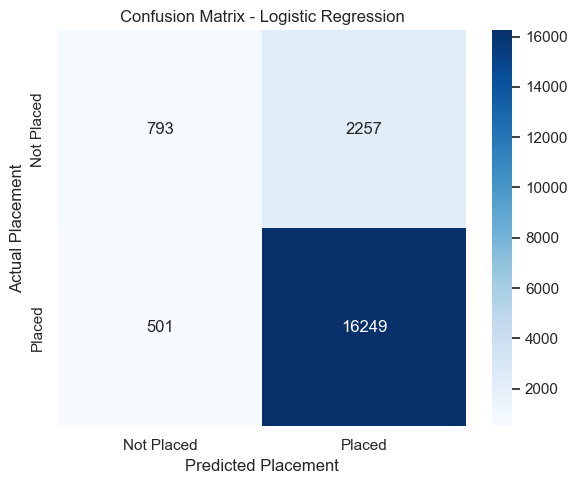

Best classification model: Logistic Regression


In [11]:
best_model_name = (
    classification_results_df
    .sort_values("F1 Score", ascending=False)
    .iloc[0]["Model"]
)

best_predictions = classification_predictions[
    best_model_name
]

confusion_data = (
    best_predictions
    .select("placed", "prediction")
    .toPandas()
)

cm = confusion_matrix(
    confusion_data["placed"],
    confusion_data["prediction"],
    labels=[0.0, 1.0]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Placed", "Placed"],
    yticklabels=["Not Placed", "Placed"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Placement")
plt.ylabel("Actual Placement")

plt.tight_layout()
plt.show()

print("Best classification model:", best_model_name)

In [12]:
from pyspark.ml.regression import (
    LinearRegression,
    DecisionTreeRegressor
)

from pyspark.ml.evaluation import RegressionEvaluator

# Select placed students with valid salaries
salary_df = df.filter(
    (F.col("placed") == 1.0) &
    F.col("salary_lpa").isNotNull() &
    (F.col("salary_lpa") > 0)
)

print("Students used for salary prediction:", salary_df.count())

# Split salary data
salary_train, salary_test = salary_df.randomSplit(
    [0.8, 0.2],
    seed=42
)

regression_models = {
    "Linear Regression": LinearRegression(
        labelCol="salary_lpa",
        featuresCol="features",
        maxIter=50
    ),

    "Decision Tree Regression": DecisionTreeRegressor(
        labelCol="salary_lpa",
        featuresCol="features",
        maxDepth=5,
        seed=42
    )
}

regression_results = []
regression_predictions = {}
regression_fitted_models = {}

for model_name, model in regression_models.items():

    pipeline = Pipeline(
        stages=make_preprocessing_stages() + [model]
    )

    fitted_model = pipeline.fit(salary_train)

    predictions = fitted_model.transform(salary_test)

    # Evaluate regression performance
    rmse_evaluator = RegressionEvaluator(
        labelCol="salary_lpa",
        predictionCol="prediction",
        metricName="rmse"
    )

    mae_evaluator = RegressionEvaluator(
        labelCol="salary_lpa",
        predictionCol="prediction",
        metricName="mae"
    )

    r2_evaluator = RegressionEvaluator(
        labelCol="salary_lpa",
        predictionCol="prediction",
        metricName="r2"
    )

    rmse = rmse_evaluator.evaluate(predictions)
    mae = mae_evaluator.evaluate(predictions)
    r2 = r2_evaluator.evaluate(predictions)

    regression_results.append({
        "Model": model_name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

    regression_predictions[model_name] = predictions
    regression_fitted_models[model_name] = fitted_model

    print("\nModel:", model_name)
    print("RMSE:", round(rmse, 3))
    print("MAE:", round(mae, 3))
    print("R2:", round(r2, 3))

regression_results_df = pd.DataFrame(
    regression_results
)

regression_results_df

Students used for salary prediction: 84432

Model: Linear Regression
RMSE: 1.038
MAE: 0.875
R2: 0.834

Model: Decision Tree Regression
RMSE: 1.727
MAE: 1.381
R2: 0.541


,Model,RMSE,MAE,R2
0,Linear Regression,1.038099,0.874826,0.834121
1,Decision Tree Regression,1.727064,1.381456,0.540876


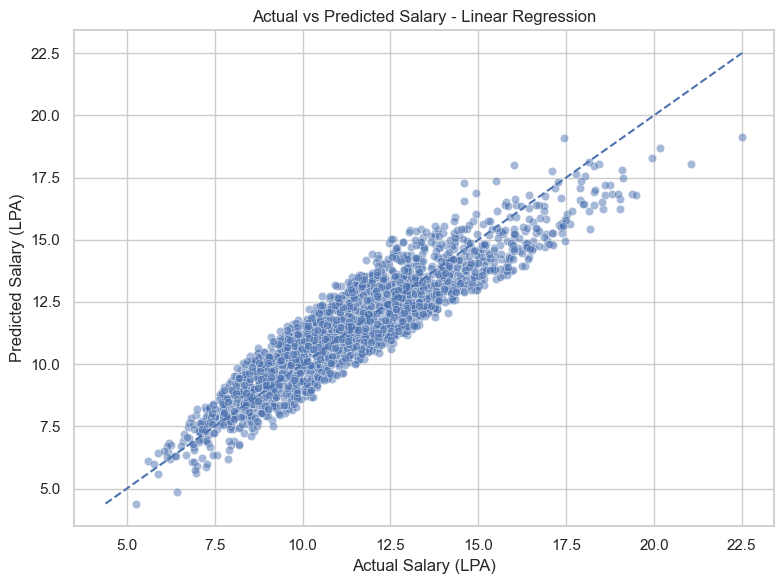

Best salary model: Linear Regression


In [13]:
best_regression_name = (
    regression_results_df
    .sort_values("RMSE", ascending=True)
    .iloc[0]["Model"]
)

best_salary_predictions = regression_predictions[
    best_regression_name
]

salary_plot_data = (
    best_salary_predictions
    .select("salary_lpa", "prediction")
    .toPandas()
)

# Sample for readability
if len(salary_plot_data) > 2000:
    salary_plot_data = salary_plot_data.sample(
        2000,
        random_state=42
    )

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=salary_plot_data,
    x="salary_lpa",
    y="prediction",
    alpha=0.5
)

# Perfect prediction reference line
minimum = min(
    salary_plot_data["salary_lpa"].min(),
    salary_plot_data["prediction"].min()
)

maximum = max(
    salary_plot_data["salary_lpa"].max(),
    salary_plot_data["prediction"].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title(f"Actual vs Predicted Salary - {best_regression_name}")
plt.xlabel("Actual Salary (LPA)")
plt.ylabel("Predicted Salary (LPA)")

plt.tight_layout()
plt.show()

print("Best salary model:", best_regression_name)

In [14]:
from pyspark.ml.clustering import KMeans
from pyspark.ml.feature import StandardScaler, VectorAssembler
from pyspark.ml.evaluation import ClusteringEvaluator

cluster_features = [
    "ssc_percentage",
    "hsc_percentage",
    "degree_percentage",
    "technical_skills_score",
    "soft_skills_score",
    "aptitude_score",
    "communication_score",
    "internships_count",
    "projects_count",
    "certifications_count",
    "work_experience_months",
    "backlogs"
]

cluster_assembler = VectorAssembler(
    inputCols=cluster_features,
    outputCol="cluster_features"
)

cluster_scaler = StandardScaler(
    inputCol="cluster_features",
    outputCol="scaled_features",
    withMean=True,
    withStd=True
)

cluster_preprocessing = Pipeline(
    stages=[
        cluster_assembler,
        cluster_scaler
    ]
)

# Fit scaling on available clustering data
cluster_features_df = df.select(cluster_features).dropna()

scaled_cluster_data = cluster_preprocessing.fit(
    cluster_features_df
).transform(cluster_features_df)

cluster_evaluator = ClusteringEvaluator(
    featuresCol="scaled_features",
    predictionCol="cluster",
    metricName="silhouette"
)

silhouette_results = []

for k in [2, 3, 4, 5]:

    model = KMeans(
        featuresCol="scaled_features",
        predictionCol="cluster",
        k=k,
        seed=42
    ).fit(scaled_cluster_data)

    cluster_predictions = model.transform(
        scaled_cluster_data
    )

    score = cluster_evaluator.evaluate(
        cluster_predictions
    )

    silhouette_results.append({
        "K": k,
        "Silhouette Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

print(silhouette_df)

best_k = int(
    silhouette_df.sort_values(
        "Silhouette Score",
        ascending=False
    ).iloc[0]["K"]
)

print("Best K:", best_k)

   K  Silhouette Score
0  2          0.243083
1  3          0.222738
2  4          0.187343
3  5          0.183711
Best K: 2


In [16]:
print("=" * 60)
print("CAMPUS PLACEMENT PREDICTION - FINAL RESULTS")
print("=" * 60)

# 1. Classification results
print("\nCLASSIFICATION RESULTS")

print(
    classification_results_df.sort_values(
        "F1 Score",
        ascending=False
    ).to_string(index=False)
)

print("\nBest Classification Model:", best_model_name)


# 2. Salary regression results
print("\nSALARY REGRESSION RESULTS")

print(
    regression_results_df.sort_values(
        "RMSE",
        ascending=True
    ).to_string(index=False)
)

print("\nBest Salary Prediction Model:", best_regression_name)


# 3. Student clustering results
print("\nSTUDENT CLUSTERING RESULTS")

# Check whether cluster_summary has been created
if "cluster_summary" in globals():
    cluster_summary.show(truncate=False)
else:
    print("Cluster summary is not available.")
    print("Please run the K-means clustering summary cell first.")


# 4. K-means silhouette comparison
print("\nK-MEANS SILHOUETTE RESULTS")

print(
    silhouette_df.sort_values(
        "Silhouette Score",
        ascending=False
    ).to_string(index=False)
)


# 5. Project completion message
print("\n" + "=" * 60)
print("PROJECT EXECUTION COMPLETED")
print("=" * 60)

CAMPUS PLACEMENT PREDICTION - FINAL RESULTS

CLASSIFICATION RESULTS
              Model  Accuracy  Precision   Recall  F1 Score
Logistic Regression  0.860707   0.878040 0.970090  0.921772
      Decision Tree  0.851667   0.857720 0.988657  0.918546
                SVM  0.845960   0.845960 1.000000  0.916553
        Naive Bayes  0.697071   0.890698 0.731701  0.803409

Best Classification Model: Logistic Regression

SALARY REGRESSION RESULTS
                   Model     RMSE      MAE       R2
       Linear Regression 1.038099 0.874826 0.834121
Decision Tree Regression 1.727064 1.381456 0.540876

Best Salary Prediction Model: Linear Regression

STUDENT CLUSTERING RESULTS
Cluster summary is not available.
Please run the K-means clustering summary cell first.

K-MEANS SILHOUETTE RESULTS
 K  Silhouette Score
 2          0.243083
 3          0.222738
 4          0.187343
 5          0.183711

PROJECT EXECUTION COMPLETED
